In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
df = pd.read_csv("iris.csv")

print("Dataset Loaded Successfully")

display(df.head())

Dataset Loaded Successfully


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [6]:
import pandas as pd

df = pd.read_csv("iris.csv")

print("Dataset Loaded Successfully")
display(df.head())
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nSpecies Distribution:")
print(df["species"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Loaded Successfully


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Statistical Summary:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


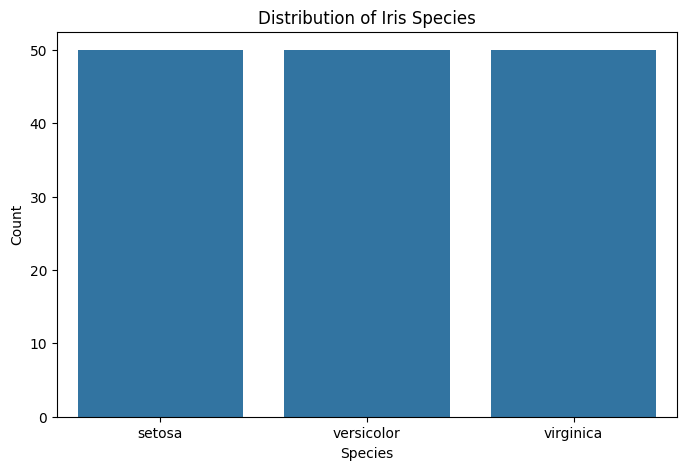

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")

plt.savefig("outputs/species_distribution.png")
plt.show()

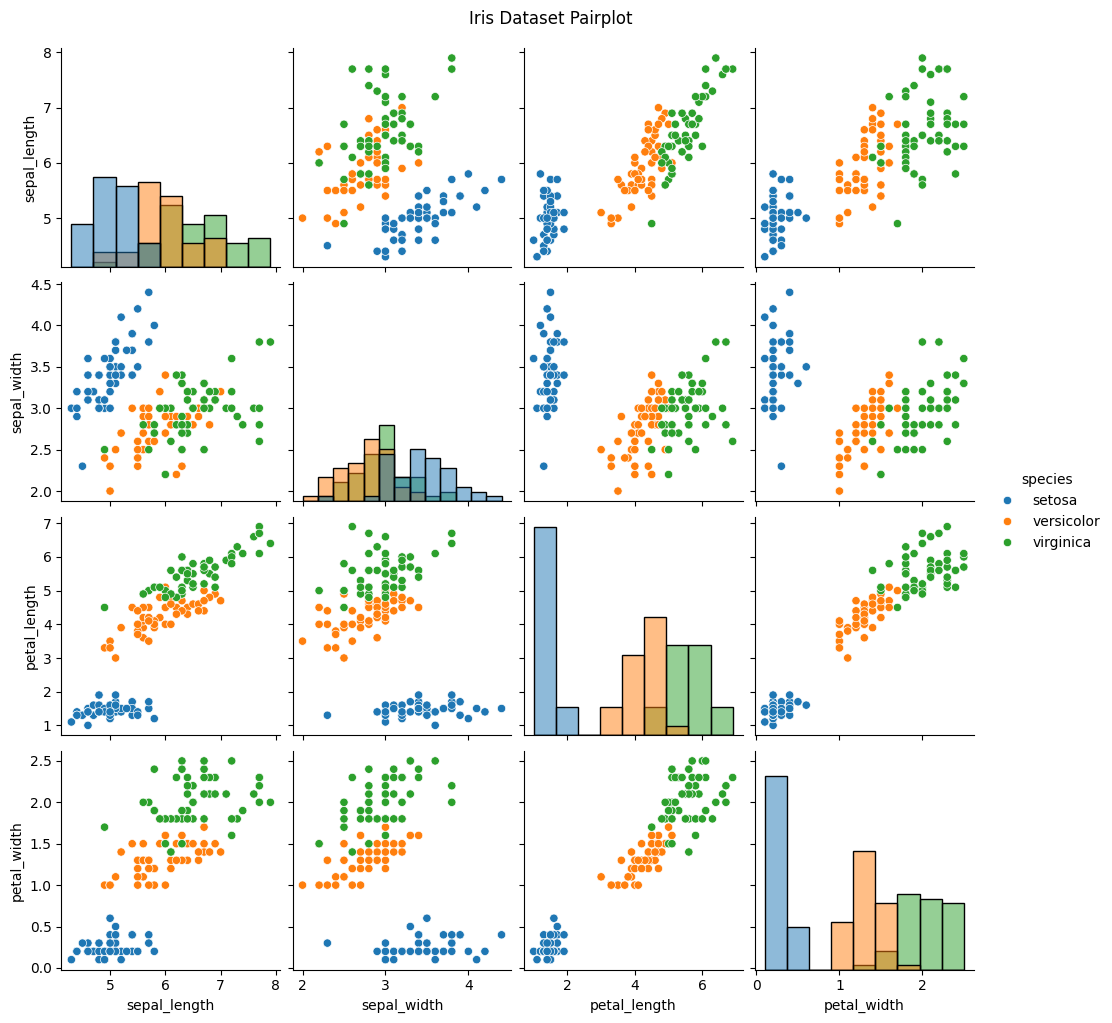

In [8]:
sns.pairplot(df, hue="species", diag_kind="hist")

plt.suptitle("Iris Dataset Pairplot", y=1.02)

plt.savefig("outputs/pairplot.png")
plt.show()

In [9]:
X = df.drop("species", axis=1)

y = df["species"]

print("Input Features:")
display(X.head())

print("\nTarget Variable:")
display(y.head())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features:


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target Variable:


0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


Feature Shape: (150, 4)
Target Shape: (150,)


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

print("Feature Scaling Completed Successfully")

display(X_scaled.head())
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset Splitting Completed")

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Feature Scaling Completed Successfully


,sepal_length,sepal_width,petal_length,petal_width
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


Dataset Splitting Completed
Training Features: (120, 4)
Testing Features: (30, 4)
Training Labels: (120,)
Testing Labels: (30,)


In [12]:
log_model = LogisticRegression(max_iter=200)

log_model.fit(X_train, y_train)

log_predictions = log_model.predict(X_test)

print("Logistic Regression Model Trained Successfully")

print("\nPredicted Values:")
print(log_predictions)

print("\nActual Values:")
print(y_test.values)

Logistic Regression Model Trained Successfully

Predicted Values:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']

Actual Values:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'virginica'
 'virginica' 'versicolor' 'versicolor' 'setosa' 'virginica' 'setosa']


In [14]:
tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)

print("Decision Tree Model Trained Successfully")

print("\nPredicted Values:")
print(tree_predictions)

print("\nActual Values:")
print(y_test.values)

Decision Tree Model Trained Successfully

Predicted Values:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']

Actual Values:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'virginica'
 'virginica' 'versicolor' 'versicolor' 'setosa' 'virginica' 'setosa']


Training samples: 120
Testing samples: 30

Classification Benchmark Results:
              Model  Accuracy  Precision   Recall  F1-Score
Logistic Regression  0.933333   0.933333 0.933333  0.933333
      Decision Tree  0.933333   0.933333 0.933333  0.933333

Logistic Regression Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro

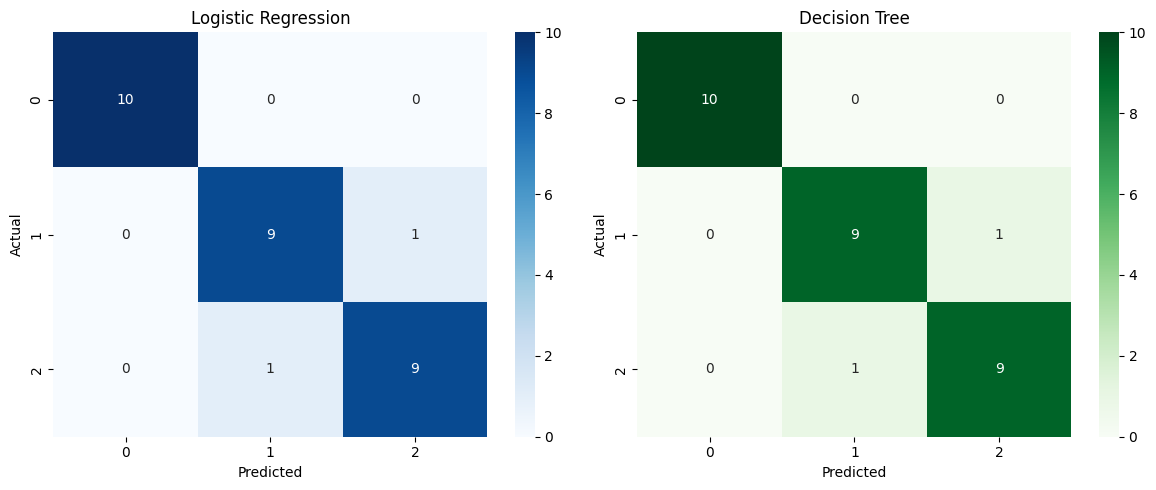

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

df = pd.read_csv("iris.csv")

X = df.drop("species", axis=1)
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

log_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=500))
])

tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)

log_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)

log_predictions = log_model.predict(X_test)
tree_predictions = tree_model.predict(X_test)

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, log_predictions),
        accuracy_score(y_test, tree_predictions)
    ],
    "Precision": [
        precision_score(y_test, log_predictions, average="weighted"),
        precision_score(y_test, tree_predictions, average="weighted")
    ],
    "Recall": [
        recall_score(y_test, log_predictions, average="weighted"),
        recall_score(y_test, tree_predictions, average="weighted")
    ],
    "F1-Score": [
        f1_score(y_test, log_predictions, average="weighted"),
        f1_score(y_test, tree_predictions, average="weighted")
    ]
})

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nClassification Benchmark Results:")
print(results.to_string(index=False))

print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, log_predictions))

print("\nDecision Tree Classification Report:")
print(classification_report(y_test, tree_predictions))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, log_predictions),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, tree_predictions),
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig("outputs/confusion_matrices.png")
plt.show()

In [5]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)

print("Decision Tree Model Trained Successfully")

print("\nPredicted Values:")
print(tree_predictions)

print("\nActual Values:")
print(y_test.values)

Decision Tree Model Trained Successfully

Predicted Values:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']

Actual Values:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'virginica'
 'virginica' 'versicolor' 'versicolor' 'setosa' 'virginica' 'setosa']


In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression": log_predictions,
    "Decision Tree": tree_predictions
}

results = []

for model_name, predictions in models.items():

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, average="weighted"
    )

    recall = recall_score(
        y_test, predictions, average="weighted"
    )

    f1 = f1_score(
        y_test, predictions, average="weighted"
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,Decision Tree,0.933333,0.933333,0.933333,0.933333


<Figure size 1000x600 with 0 Axes>

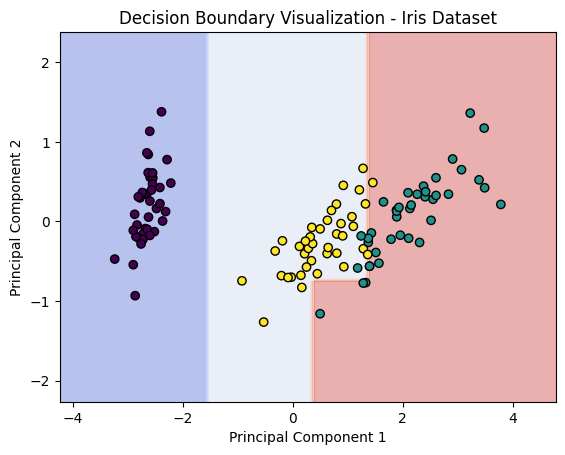

In [7]:
from sklearn.decomposition import PCA
from sklearn.inspection import DecisionBoundaryDisplay

pca = PCA(n_components=2)

X_train_2d = pca.fit_transform(X_train)
X_test_2d = pca.transform(X_test)

boundary_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)

boundary_model.fit(X_train_2d, y_train)

plt.figure(figsize=(10, 6))

DecisionBoundaryDisplay.from_estimator(
    boundary_model,
    X_train_2d,
    response_method="predict",
    cmap=plt.cm.coolwarm,
    alpha=0.4
)

plt.scatter(
    X_train_2d[:, 0],
    X_train_2d[:, 1],
    c=pd.factorize(y_train)[0],
    edgecolor="black"
)

plt.title("Decision Boundary Visualization - Iris Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.savefig("outputs/decision_boundary.png")
plt.show()

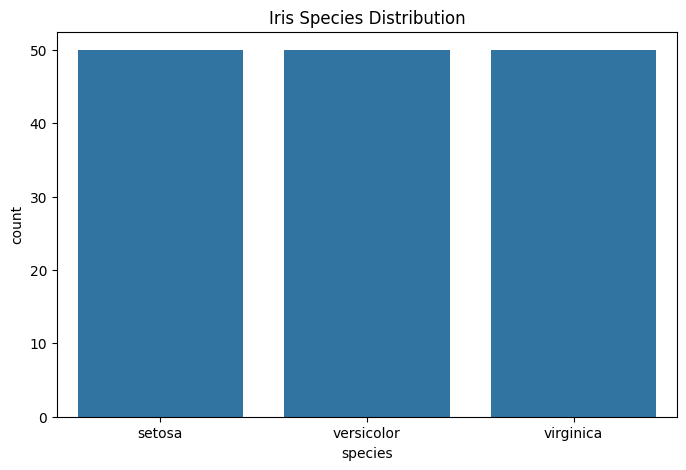

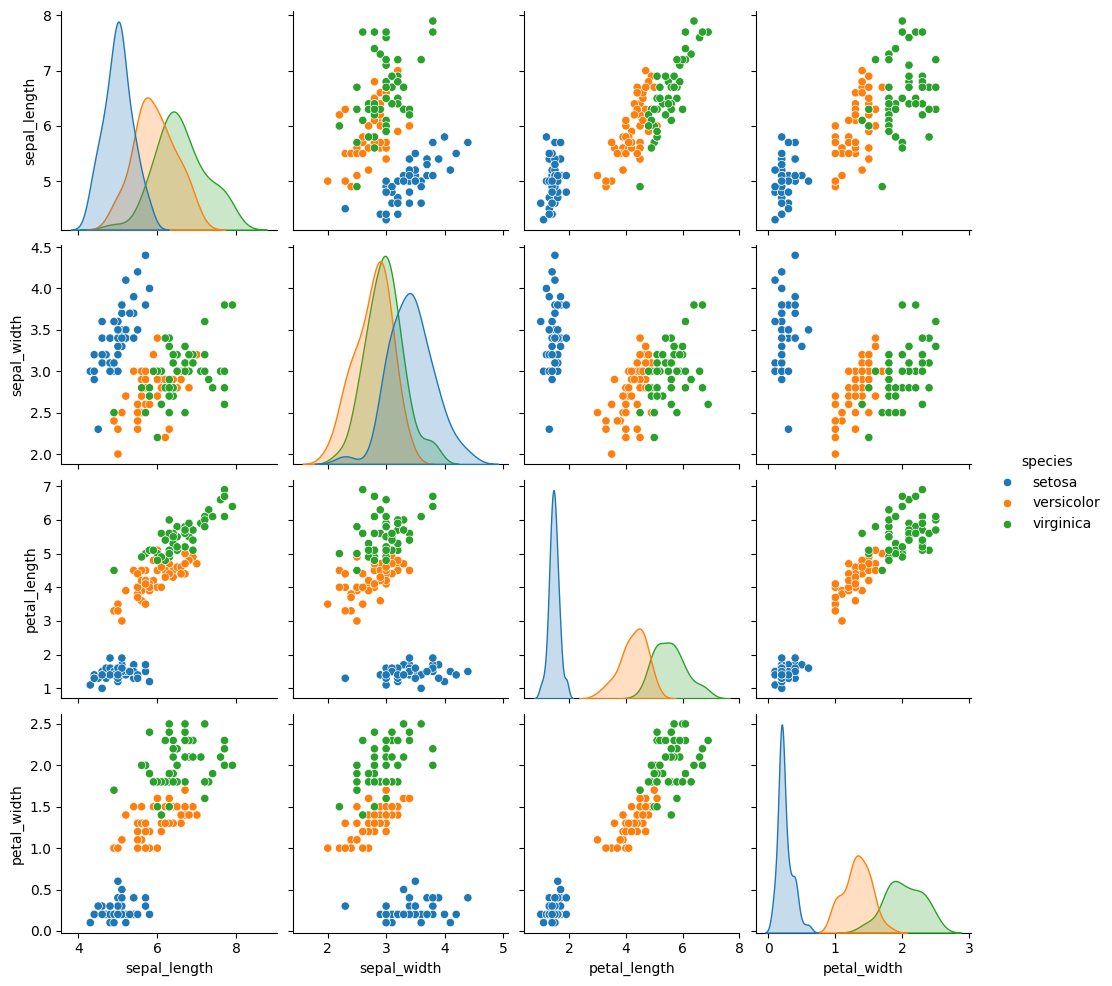

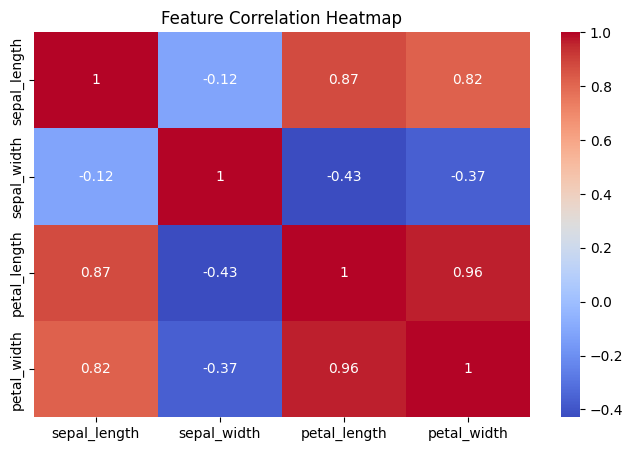

All graphs saved successfully!


In [8]:
import os

os.makedirs("outputs", exist_ok=True)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="species")
plt.title("Iris Species Distribution")
plt.savefig("outputs/species_distribution.png")
plt.show()

sns.pairplot(df, hue="species")
plt.savefig("outputs/pairplot.png")
plt.show()

plt.figure(figsize=(8, 5))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.savefig("outputs/correlation_heatmap.png")
plt.show()

print("All graphs saved successfully!")